# Бейзлайн: Top-Pop против ALS

**Задача.** Порекомендовать пользователю K товаров, которые он кликнет (`tap` после показа `seen`, т.е. `click` после `view`).

**Сравниваем три подхода:**
1. **Глобальный Top-Pop по популярности** (числу показов на train) — классический бейзлайн без персонализации.
2. **Top-Pop по кластеру**: на train для каждого товара считаем сглаженную конверсию
   `CTR = (clicks + α·CTR_global) / (views + α)` (α = 100 «виртуальных» показов не даёт товару «1 клик на 3 показа» обгонять стабильные)
   и отдаём каждому пользователю топ-K товаров **его соцдем-кластера**.
3. **ALS** (implicit, factors=64, 20 итераций): матричная факторизация матрицы «пользователь × товар»,
   построенной по **всем событиям train с разными весами и затуханием по времени**:
   `view = 0.1 < click = 1 < like = 3 < clickout (переход к покупке) = 5`, вес умножается на
   `0.5^(возраст_дней / 30)` — событие месячной давности весит вдвое меньше вчерашнего.
   Учит и глобальную популярность, и персональные предпочтения.

**Режим сравнения.** Seen-фильтр отключён для всех методов: каждый отдаёт свой «сырой» топ-K
(включая товары, которые пользователь уже видел) — сравниваем чистое качество ранжирования.

**Оценка.** Test = последние 7 дней событий (сплит по времени, без утечек; по правилу T-ECD
отбрасываем последние 12 часов). Метрики по фактическим кликам: Recall@K, Precision@K, HitRate@K.

In [1]:
%matplotlib inline

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data/raw")
EVENTS_DIR = DATA_DIR / "dataset/small/marketplace/events"

df_users = pd.read_parquet(DATA_DIR / "dataset/full/users.pq")  # user_id, socdem_cluster, region

# subdomain и os для бейзлайна не нужны — не читаем их вовсе (экономия ~4 ГБ RAM)
df = pd.concat(
    [pd.read_parquet(f, columns=["user_id", "item_id", "action_type", "timestamp"])
     for f in sorted(EVENTS_DIR.glob("*.pq"))],
    ignore_index=True,
)
df["item_id"] = df["item_id"].astype("category")
df["action_type"] = df["action_type"].astype("category")
df["day"] = df["timestamp"].dt.days.astype("int32")
df["hour"] = df["timestamp"].dt.components["hours"].astype("int8")
df = df.drop(columns="timestamp")

# Компактные коды для матрицы взаимодействий (до сплита — коды общие для train/test)
df["uid"] = pd.factorize(df["user_id"])[0].astype("int32")
df["iid"] = df["item_id"].cat.codes.astype("int32")

# Пригодится после освобождения df: справочник iid -> item_id и размеры матрицы
ITEM_IDS = df["item_id"].cat.categories.to_numpy()
N_USERS = int(df["uid"].max()) + 1
N_ITEMS = int(ITEM_IDS.size)

print(f"events: {df.shape[0]:,} | дни: {df['day'].min()}..{df['day'].max()}")
df.head()

events: 130,447,117 | дни: 1082..1308


,user_id,item_id,action_type,day,hour,uid,iid
0,59328774,nfmcg_14777696,view,1082,0,0,431094
1,66295302,nfmcg_26098539,view,1082,0,1,1453270
2,37542104,nfmcg_10840247,view,1082,0,2,75877
3,35193548,nfmcg_8040572,view,1082,0,3,2149373
4,27256137,nfmcg_6770239,view,1082,0,4,2034451


In [3]:
# Временной сплит: test = последние 7 дней.
# Правило T-ECD: последние 12 часов содержат временной шум — отбрасываем их.
import gc

LAST_DAY = df["day"].max()
TEST_DAYS = 7

df = df[~((df["day"] == LAST_DAY) & (df["hour"] >= 12))]

train = df[df["day"] <= LAST_DAY - TEST_DAYS]
test = df[df["day"] > LAST_DAY - TEST_DAYS]
del df  # дальше нужны только train/test — освобождаем ~4.5 ГБ до обучения
gc.collect()

for name, part in [("train", train), ("test", test)]:
    print(f"{name}: {len(part):,} событий, {part['user_id'].nunique():,} пользователей, "
          f"{part['item_id'].nunique():,} товаров")

train: 126,806,432 событий, 1,596,534 пользователей, 2,235,873 товаров
test: 3,408,821 событий, 229,494 пользователей, 368,376 товаров


In [4]:
%%time
# Сглаженная конверсия seen→tap на train по парам (кластер, товар)

ALPHA = 100  # сила сглаживания: столько «виртуальных» показов с глобальной конверсией добавляем

glob_ctr = (train["action_type"] == "click").sum() / (train["action_type"] == "view").sum()
print(f"глобальная конверсия: {glob_ctr:.4f}")

tr = train.merge(df_users[["user_id", "socdem_cluster"]], on="user_id", how="left")
pair = tr.pivot_table(
    index=["socdem_cluster", "item_id"], columns="action_type",
    values="user_id", aggfunc="size", fill_value=0, observed=True,
).reset_index()
for a in ["view", "click"]:
    if a not in pair:
        pair[a] = 0
pair["ctr"] = (pair["click"] + ALPHA * glob_ctr) / (pair["view"] + ALPHA)
del tr; gc.collect()  # объединённая копия train больше не нужна (~4 ГБ)

# Товар глобально (для контраста топов)
item_glob = pair.groupby("item_id", observed=True)[["view", "click"]].sum()
item_glob["ctr"] = (item_glob["click"] + ALPHA * glob_ctr) / (item_glob["view"] + ALPHA)

print(f"пар кластер×товар: {len(pair):,}")
pair.head()

глобальная конверсия: 0.0303


пар кластер×товар: 6,672,479
CPU times: user 18.5 s, sys: 2.17 s, total: 20.6 s
Wall time: 22.4 s


action_type,socdem_cluster,item_id,click,clickout,like,view,ctr
0,0.0,nfmcg_10000147,1,0,0,0,0.040283
1,0.0,nfmcg_10000156,0,0,0,2,0.029689
2,0.0,nfmcg_10000262,0,0,0,1,0.029983
3,0.0,nfmcg_10000298,0,0,0,1,0.029983
4,0.0,nfmcg_10000326,1,1,0,37,0.029403


**Топ по кластеру.** Берём с запасом (×20 к K): часть товаров пользователь уже видел — выкинем при выдаче.
Пользователям без кластера достаётся топ по глобальной конверсии.

In [5]:
K = 20        # размер рекомендаций
RESERVE = 20  # запас кандидатов до фильтра «уже видел»

# 1) глобальный топ по популярности
top_pop_views = item_glob.nlargest(K * RESERVE, "view").index.to_list()

# 2) топ по конверсии внутри каждого кластера
top_by_cluster = {
    cl: g.nlargest(K * RESERVE, "ctr")["item_id"].to_list()
    for cl, g in pair.groupby("socdem_cluster", observed=True)
}
top_pop_ctr = item_glob.nlargest(K * RESERVE, "ctr").index.to_list()

cluster_of = df_users.set_index("user_id")["socdem_cluster"]

def rec_for_cluster(cl) -> list:
    return top_by_cluster.get(cl, top_pop_ctr)

print("кластеров с топом:", len(top_by_cluster))

кластеров с топом: 21


## ALS

Матрица взаимодействий — **все события train с весами по типу и затуханием по возрасту**:

- `view = 0.1 < click = 1 < like = 3 < clickout = 5` (переход к покупке — самый сильный сигнал);
- затухающий счётчик: вес события умножается на `0.5^(возраст_дней / 30)` (период полураспада 30 дней);
- повторные события одного пользователя с одним товаром суммируются.

Матрица вырастает с 3.4 млн (только клики) до ~90 млн ненулевых (~1 ГБ), факторы 64 — ещё ~1 ГБ:
по памяти помещается, но каждая итерация становится в разы дольше.

In [6]:
%%time
import implicit
from scipy.sparse import coo_matrix

# Веса типов событий и затухание (событие месяц назад весит вдвое меньше)
W = {"view": 0.1, "click": 1.0, "like": 3.0, "clickout": 5.0}
HALF_LIFE = 30  # дней

age = (train["day"].max() - train["day"]).to_numpy(dtype="float32")
weights = (
    train["action_type"].map(W).to_numpy(dtype="float32")
    * np.power(np.float32(0.5), age / HALF_LIFE)
)

user_items = coo_matrix(
    (weights, (train["uid"], train["iid"])),
    shape=(N_USERS, N_ITEMS),
).tocsr()  # повторные (user, item) суммируются
print(f"матрица: {user_items.shape[0]:,} x {user_items.shape[1]:,}, nnz = {user_items.nnz:,}")

del age, weights, train
gc.collect()  # на время обучения в памяти остаётся только матрица и факторы

model = implicit.als.AlternatingLeastSquares(
    factors=64, iterations=20, regularization=0.01, random_state=32,
)
model.fit(user_items)
print("user_factors:", model.user_factors.shape, "| item_factors:", model.item_factors.shape)

матрица: 1,616,763 x 2,325,409, nnz = 83,715,232


100%|██████████| 20/20 [14:18<00:00, 42.77s/it]

user_factors: (1616763, 64) | item_factors: (2325409, 64)
CPU times: user 14min 23s, sys: 2.4 s, total: 14min 25s
Wall time: 14min 26s


In [7]:
%%time
# Цель: товары, которые пользователь кликнул в test
test_clicks = (
    test[test["action_type"] == "click"]
    .groupby("user_id", observed=True)["item_id"].agg(set)
)
print(f"оцениваем {len(test_clicks):,} пользователей с кликами в test")

# uid берём из test: коды общие с train (factorize делали до сплита)
uid_of = test.groupby("user_id", observed=True)["uid"].first()
uids = uid_of.reindex(test_clicks.index).to_numpy().astype("int32")

# Рекомендации ALS — батчами (скор всех товаров 2.3М сразу для всех пользователей не влезает в RAM).
# N=K: seen-фильтр отключён, оценка берёт ровно топ-K — запас кандидатов не нужен
BATCH = 100_000
rows = []
for start in range(0, len(uids), BATCH):
    chunk = uids[start:start + BATCH]
    ids, _ = model.recommend(chunk, user_items[chunk], N=K,
                             filter_already_liked_items=False)
    rows.append(ids)
ids = np.vstack(rows)  # (n_users, K) кодов iid
del rows

als_recs = {u: ITEM_IDS[row] for u, row in zip(test_clicks.index, ids)}  # -> item_id
print("рекомендаций ALS:", len(als_recs))

оцениваем 15,714 пользователей с кликами в test


рекомендаций ALS: 15714
CPU times: user 34.6 s, sys: 170 ms, total: 34.8 s
Wall time: 27.2 s


## Оценка на test

Одинаковые условия для всех: «сырой» топ-K без seen-фильтра, пересечение с фактическими кликами test.

In [8]:
def evaluate(get_candidates) -> dict:
    """get_candidates(user_id) -> ранжированный список товаров; метрики по кликам test."""
    hits, hit_users, denom = 0, 0, 0
    for user, target in test_clicks.items():
        rec = get_candidates(user)[:K]
        h = len(set(rec) & target)
        hits += h
        denom += len(target)
        hit_users += h > 0
    n = len(test_clicks)
    return {
        "Recall@K": hits / denom,
        "Precision@K": hits / (n * K),
        "HitRate@K": hit_users / n,
        "users": n,
    }

variants = {
    "1. глобальный топ по популярности": lambda u: top_pop_views,
    "2. топ по конверсии в кластере": lambda u: rec_for_cluster(cluster_of.get(u)),
    "3. ALS (взвеш. события + затухание, 20 итер.)": lambda u: als_recs.get(u, []),
}

results = pd.DataFrame({name: evaluate(fn) for name, fn in variants.items()}).T
results.round(4)

,Recall@K,Precision@K,HitRate@K,users
1. глобальный топ по популярности,0.0291,0.0051,0.0965,15714.0
2. топ по конверсии в кластере,0.0009,0.0002,0.0031,15714.0
"3. ALS (взвеш. события + затухание, 20 итер.)",0.0345,0.0060,0.1119,15714.0


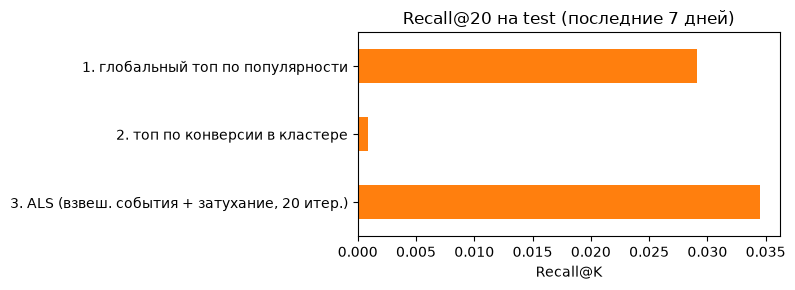

In [9]:
ax = results["Recall@K"].plot(kind="barh", figsize=(8, 3), color="tab:orange")
ax.invert_yaxis()
ax.set_title(f"Recall@{K} на test (последние {TEST_DAYS} дней)")
ax.set_xlabel("Recall@K")
plt.tight_layout()
plt.show()

## Как выглядят рекомендации бейзлайна

Топ-10 товаров двух самых крупных кластеров — с категорией и ценой из каталога.
Это же — заготовка «объяснений» для сервиса: *популярно у вашего сегмента*.

In [10]:
df_items = pd.read_parquet(
    DATA_DIR / "dataset/small/marketplace/items.pq", columns=["item_id", "category", "price"]
)

def show_top(cl, title: str) -> None:
    items = pd.DataFrame({"item_id": rec_for_cluster(cl)[:10]}).merge(df_items, on="item_id", how="left")
    items["category"] = items["category"].fillna("—")
    items.insert(0, "rank", range(1, len(items) + 1))
    display(items.style.set_caption(title).format({"price": "{:.2f}"}).hide(axis="index"))

for cl in df_users["socdem_cluster"].value_counts().index[:2]:
    show_top(cl, f"Кластер {cl:.0f} — топ товаров по конверсии seen→tap")

rank,item_id,category,price
1,nfmcg_11578367,—,0.52
2,nfmcg_20949050,Miscellaneous Goods (Uncategorized),2.06
3,nfmcg_12042740,—,2.36
4,nfmcg_16170758,Footwear of All Types,5.36
5,nfmcg_20626770,—,1.78
6,nfmcg_21045839,"Cosmetics, Personal Care, and Health Maintenance Products",2.73
7,nfmcg_5889796,"Construction and Renovation Materials, Tools, and Equipment",0.71
8,nfmcg_12379345,"Cosmetics, Personal Care, and Health Maintenance Products",0.97
9,nfmcg_741953,Footwear of All Types,2.28
10,nfmcg_11562670,"Sports Equipment, Gear, and Outdoor Activity Accessories",5.12


rank,item_id,category,price
1,nfmcg_22099003,"Cosmetics, Personal Care, and Health Maintenance Products",3.72
2,nfmcg_17592177,"Cosmetics, Personal Care, and Health Maintenance Products",2.01
3,nfmcg_5774446,"Cosmetics, Personal Care, and Health Maintenance Products",2.94
4,nfmcg_22286295,"Cosmetics, Personal Care, and Health Maintenance Products",2.53
5,nfmcg_2721385,"Cosmetics, Personal Care, and Health Maintenance Products",1.31
6,nfmcg_15987227,"Fashion Accessories, Tech Add-ons, and Style Enhancements",2.28
7,nfmcg_5827864,"Cosmetics, Personal Care, and Health Maintenance Products",1.29
8,nfmcg_26693099,"Cosmetics, Personal Care, and Health Maintenance Products",3.66
9,nfmcg_27191910,"Fashion Accessories, Tech Add-ons, and Style Enhancements",1.68
10,nfmcg_14960851,"Cosmetics, Personal Care, and Health Maintenance Products",-0.67


## Выводы

- **Глобальный Top-Pop по популярности** — сильный бейзлайн: клики test сконцентрированы на хитах.
- **ALS на взвешенных событиях с затуханием** учит и популярность, и персональную историю (сравнение — в таблице выше).
- **Top-Pop по кластеру** остаётся мгновенным fallback-ом для холодных пользователей.
- Где расти: подбор весов типов событий и периода полураспада, категории/цены профиля пользователя, отдельная стратегия для пользователей без кластера.